## 0. Setup

In [1]:
!pip -q install lime captum kagglehub

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 455.2/455.2 kB 19.7 MB/s eta 0:00:00


In [2]:
import os, hashlib, random, copy, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from PIL import Image
from tqdm.auto import tqdm
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_recall_fscore_support,
                             f1_score, classification_report, confusion_matrix)
warnings.filterwarnings('ignore')

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

DATA_DIR = '/content/UTKFace'      # aligned-and-cropped images
OUT_DIR  = '/content/outputs'
os.makedirs(OUT_DIR, exist_ok=True)

AGE_GROUPS = ['Child', 'Teenager', 'Young adult', 'Middle-aged adult', 'Older adult']
GENDER_MAP = {0: 'Male', 1: 'Female'}                                   # UTKFace convention
RACE_MAP   = {0: 'White', 1: 'Black', 2: 'Asian', 3: 'Indian', 4: 'Others'}
MEAN, STD  = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

def age_to_group(a):
    if a <= 12: return 0
    if a <= 19: return 1
    if a <= 39: return 2
    if a <= 59: return 3
    return 4

def savefig(name):
    plt.savefig(os.path.join(OUT_DIR, name), dpi=150, bbox_inches='tight')

In [3]:
if not os.path.isdir(DATA_DIR) or len(os.listdir(DATA_DIR)) == 0:
    import kagglehub
    p = kagglehub.dataset_download('jangedoo/utkface-new')
    DATA_DIR = os.path.join(p, 'UTKFace')
print('DATA_DIR =', DATA_DIR)

DATA_DIR = /kaggle/input/datasets/jangedoo/utkface-new/UTKFace


## Task 1: Dataset Loading, Label Extraction, and Quality Assessment

In [4]:
IMG_EXT = ('.jpg', '.jpeg', '.png')
everything = sorted(os.listdir(DATA_DIR))
all_files = [f for f in everything if f.lower().endswith(IMG_EXT)]
print('Entries in directory :', len(everything))
print('Image files          :', len(all_files))
print('Non-image entries    :', len(everything) - len(all_files))
print('Example names        :', all_files[:3])

Entries in directory : 23708
Image files          : 23708
Non-image entries    : 0
Example names        : ['100_0_0_20170112213500903.jpg.chip.jpg', '100_0_0_20170112215240346.jpg.chip.jpg', '100_1_0_20170110183726390.jpg.chip.jpg']


In [5]:
def parse_name(fname):
    parts = fname.split('_')
    if len(parts) < 4:
        return None, f'malformed: {len(parts)} fields (expected age_gender_race_datetime)'
    try:
        age, g, r = int(parts[0]), int(parts[1]), int(parts[2])
    except ValueError:
        return None, 'malformed: non-integer label field'
    issues = []
    if not 0 <= age <= 116: issues.append(f'invalid age {age}')
    if g not in GENDER_MAP:  issues.append(f'invalid gender {g}')
    if r not in RACE_MAP:    issues.append(f'invalid race {r}')
    if issues: return None, '; '.join(issues)
    return dict(age=age, gender=g, race=r, datetime=parts[3].split('.')[0]), None

records, invalid = [], []
for f in tqdm(all_files, desc='parse + verify'):
    lab, err = parse_name(f)
    if err:
        invalid.append({'file': f, 'reason': err}); continue
    path = os.path.join(DATA_DIR, f)
    try:
        with open(path, 'rb') as fh: md5 = hashlib.md5(fh.read()).hexdigest()
        with Image.open(path) as im: im.verify()
        readable = True
    except Exception:
        md5, readable = None, False
    records.append({'path': path, 'file': f, **lab, 'md5': md5, 'readable': readable})

df_all = pd.DataFrame(records)
invalid_df = pd.DataFrame(invalid, columns=['file', 'reason'])

parse + verify:   0%|          | 0/23708 [00:00<?, ?it/s]

In [6]:
unreadable_df = df_all[~df_all.readable]
dup_mask = df_all.readable & df_all.duplicated('md5', keep='first')
dups_df = df_all[df_all.md5.isin(df_all.loc[dup_mask, 'md5'])].sort_values('md5')
label_conflicts = (df_all[df_all.readable].groupby('md5')[['age', 'gender', 'race']]
                   .nunique().gt(1).any(axis=1).sum())

print('Invalid / malformed filenames:'); display(invalid_df)
print('Unreadable images:', len(unreadable_df))
print('Exact duplicate files (extra copies):', int(dup_mask.sum()))
print('Duplicate groups with conflicting labels:', int(label_conflicts))
display(dups_df[['file', 'age', 'gender', 'race', 'md5']].head(10))

Invalid / malformed filenames:


,file,reason
0,39_1_20170116174525125.jpg.chip.jpg,malformed: 3 fields (expected age_gender_race_...
1,61_1_20170109142408075.jpg.chip.jpg,malformed: 3 fields (expected age_gender_race_...
2,61_1_20170109150557335.jpg.chip.jpg,malformed: 3 fields (expected age_gender_race_...


Unreadable images: 0
Exact duplicate files (extra copies): 390
Duplicate groups with conflicting labels: 259


,file,age,gender,race,md5
3040,21_0_2_20170117193634310.jpg.chip.jpg,21,0,2,009fa4c83098f3da81209b5d964947e6
3031,21_0_2_20170103234754659.jpg.chip.jpg,21,0,2,009fa4c83098f3da81209b5d964947e6
20011,58_0_3_20170119211656985.jpg.chip.jpg,58,0,3,01576199681aca21affcce48f81964a3
20017,58_0_3_20170119211703657.jpg.chip.jpg,58,0,3,01576199681aca21affcce48f81964a3
4426,24_1_0_20170105162704533.jpg.chip.jpg,24,1,0,03a2405ef52f6839ea2d6af160b83de7
11423,31_1_0_20170105162708403.jpg.chip.jpg,31,1,0,03a2405ef52f6839ea2d6af160b83de7
825,16_0_0_20170110231617005.jpg.chip.jpg,16,0,0,046bbaaa73e9f0323624704b2dda38ae
813,16_0_0_20170110231219975.jpg.chip.jpg,16,0,0,046bbaaa73e9f0323624704b2dda38ae
12284,33_0_1_20170117173931669.jpg.chip.jpg,33,0,1,04b0c53dbcaffaef6676254251fb6bab
12373,33_1_1_20170117173927950.jpg.chip.jpg,33,1,1,04b0c53dbcaffaef6676254251fb6bab


In [7]:
df = df_all[df_all.readable & ~dup_mask].drop(columns=['readable']).reset_index(drop=True)
df['age_group']   = df.age.apply(age_to_group)
df['age_group_name'] = df.age_group.map(dict(enumerate(AGE_GROUPS)))
df['gender_name'] = df.gender.map(GENDER_MAP)
df['race_name']   = df.race.map(RACE_MAP)
print(df.shape); display(df.head())

(23315, 11)


,path,file,age,gender,race,datetime,md5,age_group,age_group_name,gender_name,race_name
0,/kaggle/input/datasets/jangedoo/utkface-new/UT...,100_0_0_20170112213500903.jpg.chip.jpg,100,0,0,20170112213500903,704e6d92641cea47b2c761eeda598d73,4,Older adult,Male,White
1,/kaggle/input/datasets/jangedoo/utkface-new/UT...,100_0_0_20170112215240346.jpg.chip.jpg,100,0,0,20170112215240346,10de132769cd4dacf710a6fb89d1f715,4,Older adult,Male,White
2,/kaggle/input/datasets/jangedoo/utkface-new/UT...,100_1_0_20170110183726390.jpg.chip.jpg,100,1,0,20170110183726390,6470ba9f524e8e379fa9d6194a0aaf3c,4,Older adult,Female,White
3,/kaggle/input/datasets/jangedoo/utkface-new/UT...,100_1_0_20170112213001988.jpg.chip.jpg,100,1,0,20170112213001988,6772785ba2f5075fe42d6381030e9c6f,4,Older adult,Female,White
4,/kaggle/input/datasets/jangedoo/utkface-new/UT...,100_1_0_20170112213303693.jpg.chip.jpg,100,1,0,20170112213303693,491f6ce673dc73b6950762e0918e82c0,4,Older adult,Female,White


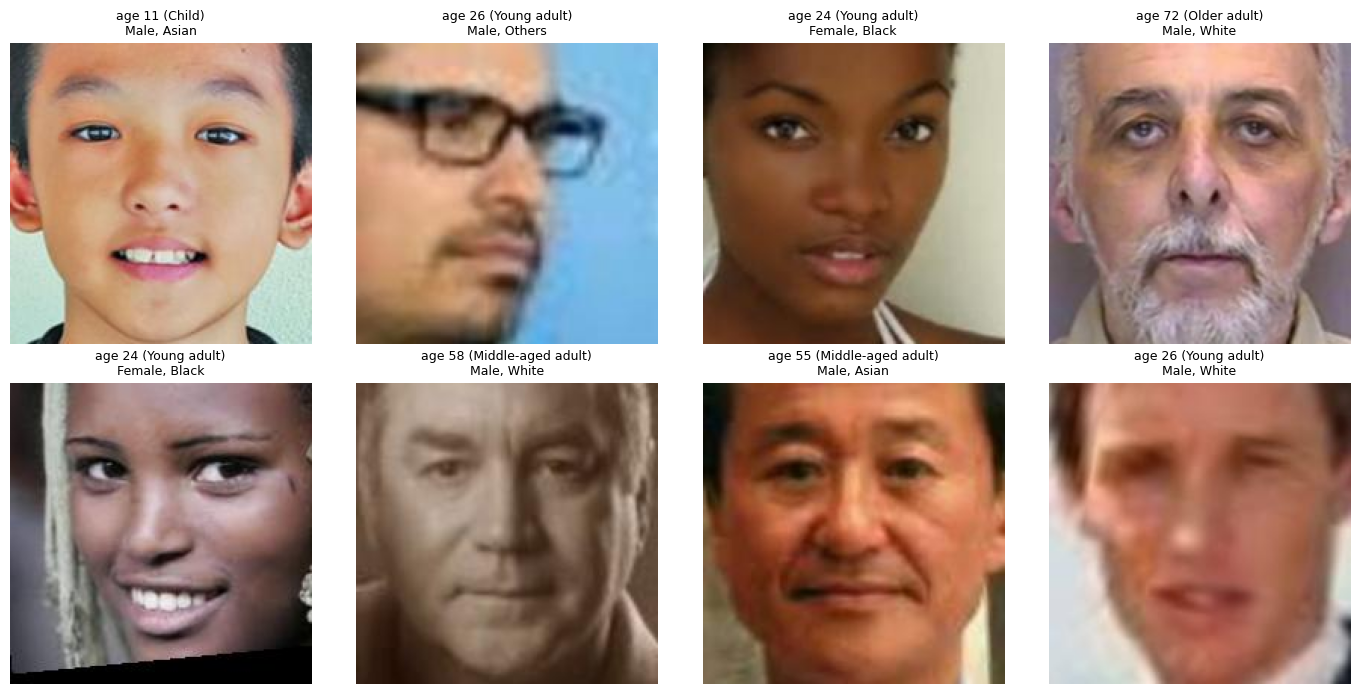

In [8]:
sample = df.sample(8, random_state=SEED)
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, (_, r) in zip(axes.ravel(), sample.iterrows()):
    ax.imshow(Image.open(r.path).convert('RGB'))
    ax.set_title(f'age {r.age} ({r.age_group_name})\n{r.gender_name}, {r.race_name}', fontsize=9)
    ax.axis('off')
plt.tight_layout(); savefig('t1_samples.png'); plt.show()

In [9]:
quality = pd.Series({
    'Total image files': len(all_files),
    'Invalid / malformed filenames': len(invalid_df),
    'Parsed records': len(df_all),
    'Unreadable images': len(unreadable_df),
    'Duplicate copies removed': int(dup_mask.sum()),
    'Total exclusions': len(all_files) - len(df),
    'Valid records retained': len(df),
}, name='count')
display(quality.to_frame())
quality.to_csv(f'{OUT_DIR}/data_quality_summary.csv')
df.to_csv(f'{OUT_DIR}/metadata_clean.csv', index=False)
invalid_df.to_csv(f'{OUT_DIR}/invalid_records.csv', index=False)

,count
Total image files,23708
Invalid / malformed filenames,3
Parsed records,23705
Unreadable images,0
Duplicate copies removed,390
Total exclusions,393
Valid records retained,23315


## Task 2: Exploratory Data Analysis

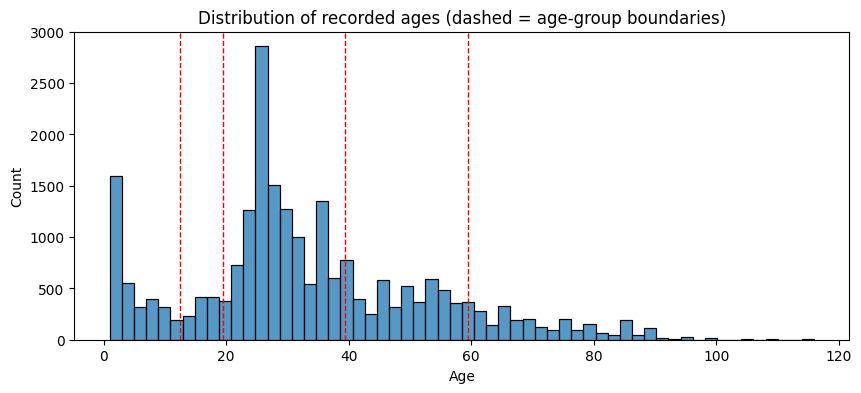

In [10]:
plt.figure(figsize=(10, 4))
sns.histplot(df.age, bins=58, kde=False)
for b in [12.5, 19.5, 39.5, 59.5]: plt.axvline(b, ls='--', c='red', lw=1)
plt.title('Distribution of recorded ages (dashed = age-group boundaries)'); plt.xlabel('Age')
savefig('t2_age_hist.png'); plt.show()

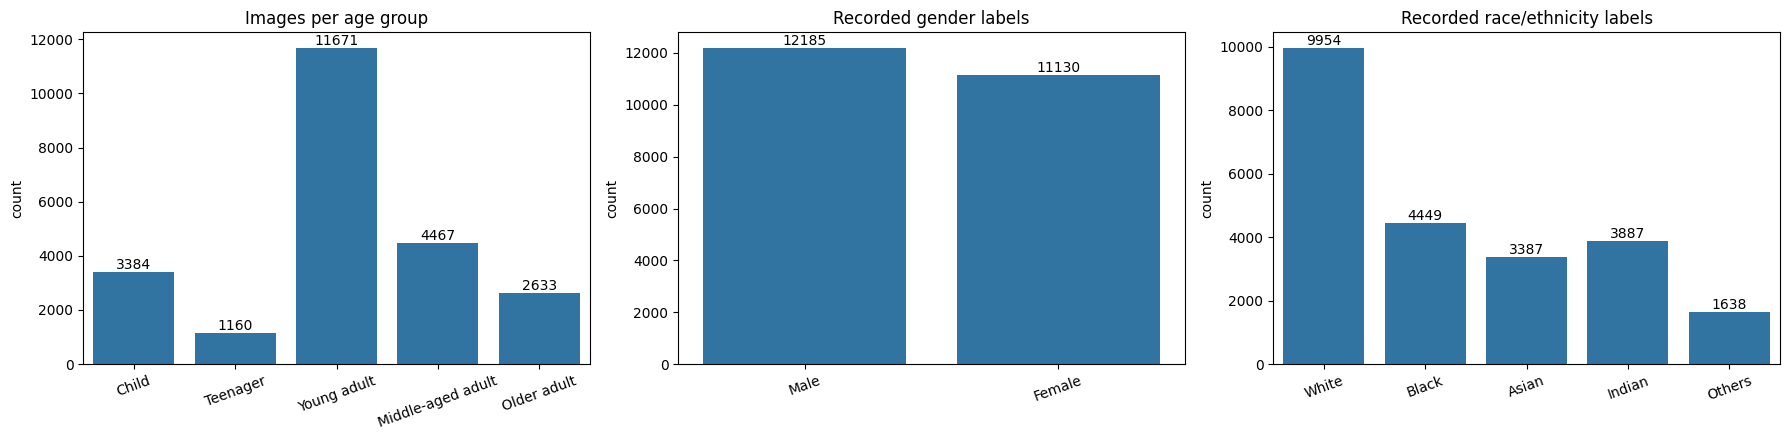

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, col, order, title in [
    (axes[0], 'age_group_name', AGE_GROUPS, 'Images per age group'),
    (axes[1], 'gender_name', list(GENDER_MAP.values()), 'Recorded gender labels'),
    (axes[2], 'race_name', list(RACE_MAP.values()), 'Recorded race/ethnicity labels')]:
    sns.countplot(data=df, x=col, order=order, ax=ax)
    ax.bar_label(ax.containers[0]); ax.set_title(title); ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=20)
plt.tight_layout(); savefig('t2_distributions.png'); plt.show()

In [12]:
ct_gender = pd.crosstab(df.age_group_name, df.gender_name, margins=True).reindex(AGE_GROUPS + ['All'])
ct_race   = pd.crosstab(df.age_group_name, df.race_name, margins=True).reindex(AGE_GROUPS + ['All'])
ct_race   = ct_race[list(RACE_MAP.values()) + ['All']]
print('Age group x recorded gender'); display(ct_gender)
print('Age group x recorded race/ethnicity'); display(ct_race)
ct_gender.to_csv(f'{OUT_DIR}/crosstab_age_gender.csv'); ct_race.to_csv(f'{OUT_DIR}/crosstab_age_race.csv')

Age group x recorded gender


gender_name,Female,Male,All
age_group_name,,,
Child,1787,1597,3384
Teenager,648,512,1160
Young adult,6233,5438,11671
Middle-aged adult,1351,3116,4467
Older adult,1111,1522,2633
All,11130,12185,23315


Age group x recorded race/ethnicity


race_name,White,Black,Asian,Indian,Others,All
age_group_name,,,,,,
Child,1320,181,949,519,415,3384
Teenager,693,153,72,118,124,1160
Young adult,3707,3064,1822,2165,913,11671
Middle-aged adult,2460,713,270,856,168,4467
Older adult,1774,338,274,229,18,2633
All,9954,4449,3387,3887,1638,23315


In [13]:
for col in ['age_group_name', 'gender_name', 'race_name']:
    vc = df[col].value_counts()
    print(f'{col:15s} most: {vc.idxmax()} ({vc.max()}, {vc.max()/len(df):.1%})   '
          f'least: {vc.idxmin()} ({vc.min()}, {vc.min()/len(df):.1%})')
cells_ = pd.crosstab(df.age_group_name, df.race_name).stack()
print(f'\nAge x race cell  most: {cells_.idxmax()} ({cells_.max()})   least: {cells_.idxmin()} ({cells_.min()})')
print(f'Imbalance ratio (largest/smallest age group): {df.age_group.value_counts().max()/df.age_group.value_counts().min():.1f}x')

age_group_name  most: Young adult (11671, 50.1%)   least: Teenager (1160, 5.0%)
gender_name     most: Male (12185, 52.3%)   least: Female (11130, 47.7%)
race_name       most: White (9954, 42.7%)   least: Others (1638, 7.0%)

Age x race cell  most: ('Young adult', 'White') (3707)   least: ('Older adult', 'Others') (18)
Imbalance ratio (largest/smallest age group): 10.1x


## Task 3: Image Preprocessing and Dataset Splitting

In [14]:
preprocess = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

class UTKDataset(Dataset):
    def __init__(self, frame, tf):
        self.paths = frame.path.tolist(); self.labels = frame.age_group.tolist(); self.tf = tf
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert('RGB')   # RGB conversion
        return self.tf(img), self.labels[i]

In [15]:
train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df.age_group, random_state=SEED)
val_df, test_df   = train_test_split(temp_df, test_size=0.50, stratify=temp_df.age_group, random_state=SEED)
train_df, val_df, test_df = [d.reset_index(drop=True) for d in (train_df, val_df, test_df)]

# leakage checks: same file path or identical bytes in two partitions
for a, b, na, nb in [(train_df, val_df, 'train', 'val'), (train_df, test_df, 'train', 'test'), (val_df, test_df, 'val', 'test')]:
    print(f'{na}/{nb}: shared paths = {len(set(a.path) & set(b.path))}, shared md5 = {len(set(a.md5) & set(b.md5))}')

counts = pd.DataFrame({n: d.age_group_name.value_counts().reindex(AGE_GROUPS) for n, d in
                       [('train', train_df), ('val', val_df), ('test', test_df)]})
pct = (counts / counts.sum() * 100).round(2).add_suffix(' %')
split_summary = pd.concat([counts, pct], axis=1)
split_summary.loc['Total'] = list(counts.sum()) + [100.0] * 3
display(split_summary)
split_summary.to_csv(f'{OUT_DIR}/split_summary.csv')
for n, d in [('train', train_df), ('val', val_df), ('test', test_df)]: d.to_csv(f'{OUT_DIR}/{n}_split.csv', index=False)

train/val: shared paths = 0, shared md5 = 0
train/test: shared paths = 0, shared md5 = 0
val/test: shared paths = 0, shared md5 = 0


,train,val,test,train %,val %,test %
age_group_name,,,,,,
Child,2369.0,507.0,508.0,14.52,14.50,14.52
Teenager,812.0,174.0,174.0,4.98,4.98,4.97
Young adult,8169.0,1751.0,1751.0,50.06,50.07,50.06
Middle-aged adult,3127.0,670.0,670.0,19.16,19.16,19.15
Older adult,1843.0,395.0,395.0,11.29,11.30,11.29
Total,16320.0,3497.0,3498.0,100.00,100.00,100.00


In [16]:
x, y = UTKDataset(train_df, preprocess)[0]
print('tensor shape:', tuple(x.shape), '| dtype:', x.dtype, '| label:', y)
print('per-channel mean after normalisation:', x.mean(dim=(1, 2)).numpy().round(3))

tensor shape: (3, 224, 224) | dtype: torch.float32 | label: 0
per-channel mean after normalisation: [1.852 1.435 1.376]


## Task 4: Model Development Using Transfer Learning

In [41]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device, torch.cuda.get_device_name(0) if device.type == 'cuda' else '')

BATCH_SIZE, LR, EPOCHS = 32, 1e-3, 5
g = torch.Generator().manual_seed(SEED)
kw = dict(batch_size=BATCH_SIZE, num_workers=2, pin_memory=(device.type == 'cuda'), persistent_workers=True)
train_loader = DataLoader(UTKDataset(train_df, preprocess), shuffle=True, generator=g, **kw)
val_loader   = DataLoader(UTKDataset(val_df, preprocess), shuffle=False, **kw)
test_loader  = DataLoader(UTKDataset(test_df, preprocess), shuffle=False, **kw)

model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
for p in model.parameters(): p.requires_grad = False       # freeze backbone
model.fc = nn.Linear(model.fc.in_features, len(AGE_GROUPS))  # new 5-way head (trainable)
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.fc.parameters(), lr=LR)
n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
n_total = sum(p.numel() for p in model.parameters())
print(f'Trainable params: {n_train:,} / {n_total:,}')

Device: cuda Tesla T4
Trainable params: 2,565 / 11,179,077


In [42]:
def run_epoch(loader, train):
    # model.eval() even while training: backbone is frozen, so BatchNorm running stats must stay
    # at their ImageNet values; fc has no dropout/BN, so eval mode does not affect its training.
    model.eval()
    tot_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for xb, yb in tqdm(loader, leave=False, desc='train' if train else 'val'):
            xb, yb = xb.to(device, non_blocking=True), yb.to(device, non_blocking=True)
            out = model(xb); loss = criterion(out, yb)
            if train:
                optimizer.zero_grad(); loss.backward(); optimizer.step()
            tot_loss += loss.item() * xb.size(0)
            correct += (out.argmax(1) == yb).sum().item(); n += xb.size(0)
    return tot_loss / n, correct / n

history, best_val_acc, best_state, best_epoch = [], -1, None, None
for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_acc = run_epoch(train_loader, True)
    va_loss, va_acc = run_epoch(val_loader, False)
    history.append(dict(epoch=epoch, train_loss=tr_loss, train_acc=tr_acc, val_loss=va_loss, val_acc=va_acc))
    if va_acc > best_val_acc:
        best_val_acc, best_epoch, best_state = va_acc, epoch, copy.deepcopy(model.state_dict())
    print(f'Epoch {epoch}/{EPOCHS} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | val loss {va_loss:.4f} acc {va_acc:.4f}')

hist_df = pd.DataFrame(history); hist_df.to_csv(f'{OUT_DIR}/training_history.csv', index=False)
torch.save(best_state, f'{OUT_DIR}/resnet18_best.pt')
print(f'\nBest validation epoch: {best_epoch} (val acc {best_val_acc:.4f}), selected on VALIDATION only')
display(hist_df)

train:   0%|          | 0/510 [00:00<?, ?it/s]

val:   0%|          | 0/110 [00:00<?, ?it/s]

Epoch 1/5 | train loss 0.8814 acc 0.6650 | val loss 0.7760 acc 0.6932


train:   0%|          | 0/510 [00:00<?, ?it/s]

val:   0%|          | 0/110 [00:00<?, ?it/s]

...

Epoch 4/5 | train loss 0.7308 acc 0.7213 | val loss 0.7353 acc 0.7086


train:   0%|          | 0/510 [00:00<?, ?it/s]

val:   0%|          | 0/110 [00:00<?, ?it/s]

Epoch 5/5 | train loss 0.7212 acc 0.7238 | val loss 0.7246 acc 0.7206

Best validation epoch: 5 (val acc 0.7206), selected on VALIDATION only


,epoch,train_loss,train_acc,val_loss,val_acc
0,1,0.881423,0.665012,0.775988,0.693166
1,2,0.775402,0.700797,0.741775,0.711467
2,3,0.745696,0.713480,0.742066,0.706606
3,4,0.730750,0.721262,0.735292,0.708607
4,5,0.721159,0.723775,0.724606,0.720618


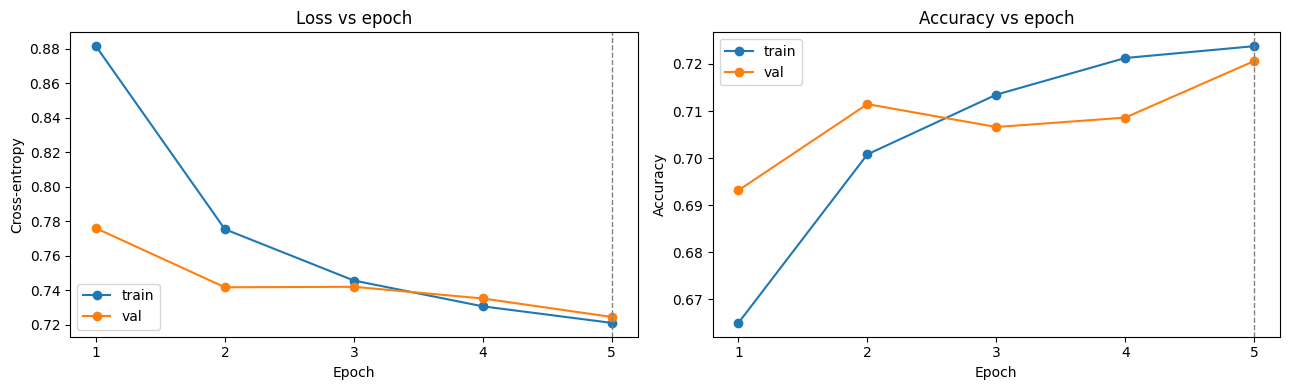

In [43]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(hist_df.epoch, hist_df.train_loss, 'o-', label='train'); ax[0].plot(hist_df.epoch, hist_df.val_loss, 'o-', label='val')
ax[0].set_title('Loss vs epoch'); ax[0].set_xlabel('Epoch'); ax[0].set_ylabel('Cross-entropy'); ax[0].legend()
ax[1].plot(hist_df.epoch, hist_df.train_acc, 'o-', label='train'); ax[1].plot(hist_df.epoch, hist_df.val_acc, 'o-', label='val')
ax[1].set_title('Accuracy vs epoch'); ax[1].set_xlabel('Epoch'); ax[1].set_ylabel('Accuracy'); ax[1].legend()
for a in ax: a.axvline(best_epoch, ls='--', c='gray', lw=1); a.set_xticks(hist_df.epoch)
plt.tight_layout(); savefig('t4_learning_curves.png'); plt.show()

## Task 5: Overall Model Evaluation

In [45]:
model.load_state_dict(best_state); model.eval()
probs = []
with torch.no_grad():
    for xb, _ in tqdm(test_loader, desc='test'):
        probs.append(torch.softmax(model(xb.to(device)), 1).cpu())
probs = torch.cat(probs).numpy()
test_df['y_true'] = test_df.age_group
test_df['y_pred'] = probs.argmax(1)
test_df['confidence'] = probs.max(1)
test_df['correct'] = test_df.y_true == test_df.y_pred
y_true, y_pred = test_df.y_true.values, test_df.y_pred.values

test:   0%|          | 0/110 [00:00<?, ?it/s]

In [21]:
acc  = accuracy_score(y_true, y_pred)
bacc = balanced_accuracy_score(y_true, y_pred)
mp, mr, mf1, _ = precision_recall_fscore_support(y_true, y_pred, average='macro', zero_division=0)
overall = pd.Series({'accuracy': acc, 'balanced_accuracy': bacc, 'macro_precision': mp,
                     'macro_recall': mr, 'macro_f1': mf1, 'n_test': len(y_true)}).round(4)
display(overall.to_frame('value'))
print(classification_report(y_true, y_pred, labels=range(5), target_names=AGE_GROUPS, digits=4, zero_division=0))

,value
accuracy,0.7173
balanced_accuracy,0.5617
macro_precision,0.6762
macro_recall,0.5617
macro_f1,0.5965
n_test,3498.0000


                   precision    recall  f1-score   support

            Child     0.8923    0.7992    0.8432       508
         Teenager     0.4925    0.1897    0.2739       174
      Young adult     0.7260    0.9172    0.8105      1751
Middle-aged adult     0.5358    0.3910    0.4521       670
      Older adult     0.7345    0.5114    0.6030       395

         accuracy                         0.7173      3498
        macro avg     0.6762    0.5617    0.5965      3498
     weighted avg     0.7031    0.7173    0.6965      3498



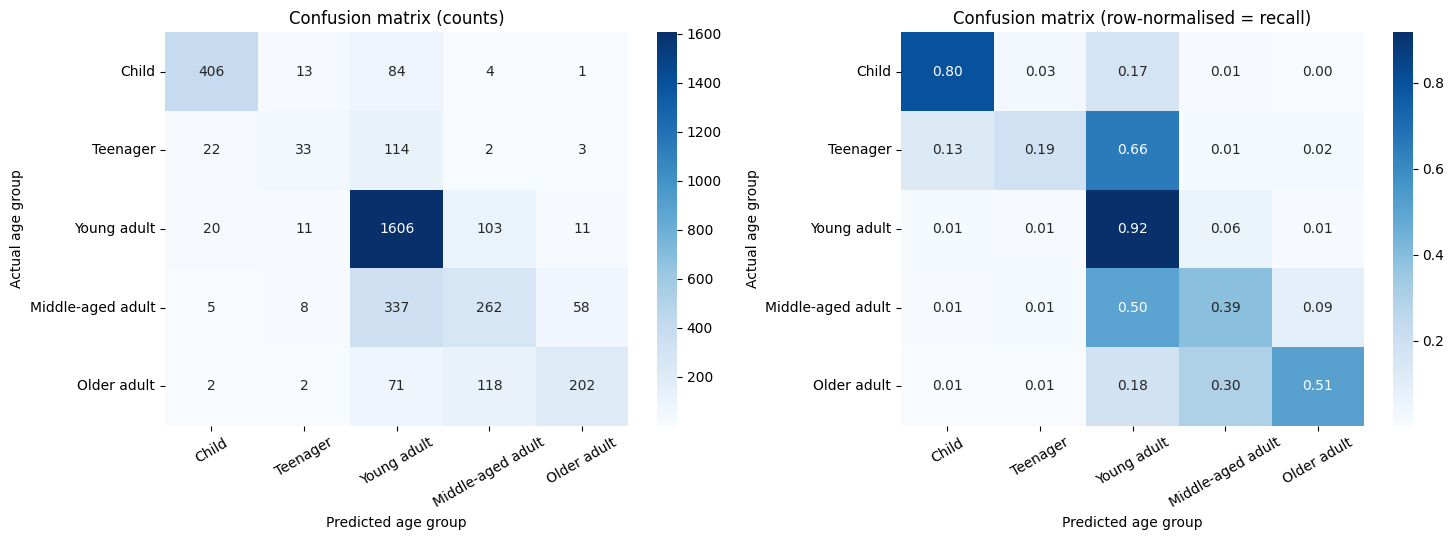

In [22]:
cm = confusion_matrix(y_true, y_pred, labels=range(5))
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=AGE_GROUPS, yticklabels=AGE_GROUPS, ax=ax[0])
sns.heatmap(cm / cm.sum(1, keepdims=True), annot=True, fmt='.2f', cmap='Blues', xticklabels=AGE_GROUPS, yticklabels=AGE_GROUPS, ax=ax[1])
ax[0].set_title('Confusion matrix (counts)'); ax[1].set_title('Confusion matrix (row-normalised = recall)')
for a in ax: a.set_xlabel('Predicted age group'); a.set_ylabel('Actual age group'); a.tick_params(axis='x', rotation=30)
plt.tight_layout(); savefig('t5_confusion_matrix.png'); plt.show()

In [23]:
rep = classification_report(y_true, y_pred, labels=range(5), target_names=AGE_GROUPS, output_dict=True, zero_division=0)
classwise = pd.DataFrame({k: rep[k] for k in AGE_GROUPS}).T.round(4)
print(f"Strongest recall: {classwise.recall.idxmax()} ({classwise.recall.max():.4f})")
print(f"Weakest recall  : {classwise.recall.idxmin()} ({classwise.recall.min():.4f})")

conf = [(AGE_GROUPS[i], AGE_GROUPS[j], cm[i, j], cm[i, j] / cm[i].sum())
        for i in range(5) for j in range(5) if i != j]
conf_df = pd.DataFrame(conf, columns=['actual', 'predicted', 'count', 'share_of_actual']).sort_values('count', ascending=False)
print('\nMost frequent confusions:'); display(conf_df.head(5).round(4))

classwise.to_csv(f'{OUT_DIR}/classwise_metrics.csv')
overall.to_csv(f'{OUT_DIR}/overall_metrics.csv', header=['value'])
conf_df.to_csv(f'{OUT_DIR}/confusion_pairs.csv', index=False)
test_df.drop(columns=['md5']).to_csv(f'{OUT_DIR}/test_predictions.csv', index=False)

Strongest recall: Young adult (0.9172)
Weakest recall  : Teenager (0.1897)

Most frequent confusions:


,actual,predicted,count,share_of_actual
14,Middle-aged adult,Young adult,337,0.5030
19,Older adult,Middle-aged adult,118,0.2987
5,Teenager,Young adult,114,0.6552
10,Young adult,Middle-aged adult,103,0.0588
1,Child,Young adult,84,0.1654


## Task 6: Demographic Subgroup Performance and Fairness Audit

In [24]:
MIN_N = 20

def subgroup_metrics(frame, col, order):
    rows = []
    for gname in order:
        s = frame[frame[col] == gname]
        if len(s) == 0: continue
        yt, yp = s.y_true.values, s.y_pred.values
        present = sorted(np.unique(yt))
        row = {col: gname, 'n_test': len(s), 'accuracy': accuracy_score(yt, yp),
               'balanced_accuracy': balanced_accuracy_score(yt, yp) if len(present) > 1 else np.nan,
               'macro_f1': f1_score(yt, yp, labels=present, average='macro', zero_division=0) if len(present) > 1 else np.nan}
        for k, an in enumerate(AGE_GROUPS):
            m = yt == k
            row[f'n_{an}'] = int(m.sum())
            row[f'recall_{an}'] = (yp[m] == k).mean() if m.sum() >= MIN_N else np.nan
        rows.append(row)
    return pd.DataFrame(rows).round(4)

gender_res = subgroup_metrics(test_df, 'gender_name', list(GENDER_MAP.values()))
race_res   = subgroup_metrics(test_df, 'race_name', list(RACE_MAP.values()))
gender_res.to_csv(f'{OUT_DIR}/subgroup_gender.csv', index=False)
race_res.to_csv(f'{OUT_DIR}/subgroup_race.csv', index=False)
main_cols = ['n_test', 'accuracy', 'balanced_accuracy', 'macro_f1']

In [25]:
print('Recorded gender-label subgroups'); display(gender_res[['gender_name'] + main_cols])
print('Recorded race/ethnicity-label subgroups'); display(race_res[['race_name'] + main_cols])

Recorded gender-label subgroups


,gender_name,n_test,accuracy,balanced_accuracy,macro_f1
0,Male,1860,0.6995,0.5821,0.6115
1,Female,1638,0.7375,0.5125,0.5510


Recorded race/ethnicity-label subgroups


,race_name,n_test,accuracy,balanced_accuracy,macro_f1
0,White,1502,0.6398,0.5717,0.5946
1,Black,667,0.7691,0.4823,0.5130
2,Asian,533,0.8330,0.5247,0.5557
3,Indian,573,0.7225,0.5113,0.5414
4,Others,223,0.7937,0.4722,0.5045


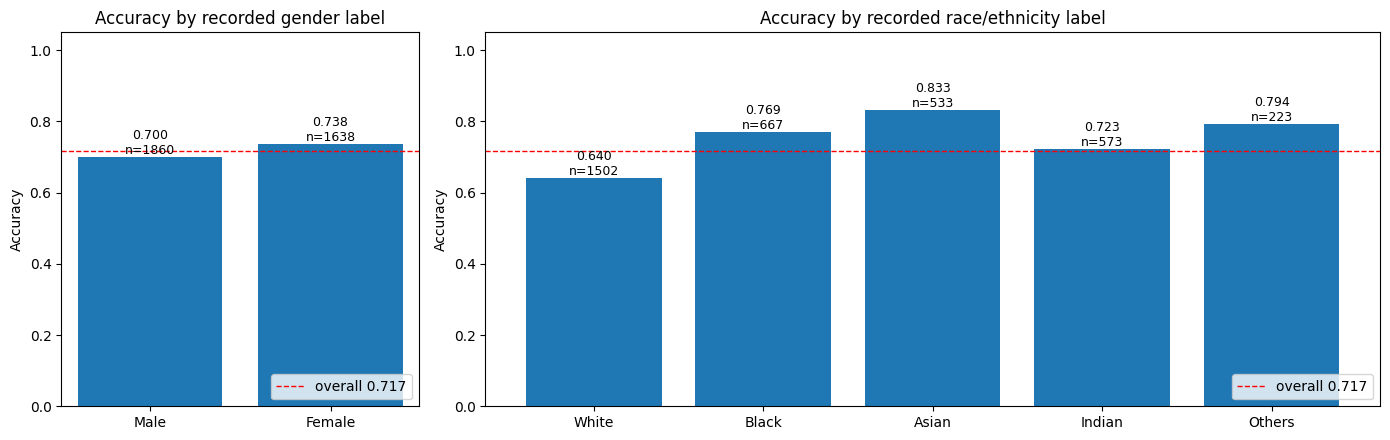

In [26]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={'width_ratios': [2, 5]})
for a, res, col, title in [(ax[0], gender_res, 'gender_name', 'Accuracy by recorded gender label'),
                           (ax[1], race_res, 'race_name', 'Accuracy by recorded race/ethnicity label')]:
    bars = a.bar(res[col], res.accuracy)
    a.bar_label(bars, labels=[f'{v:.3f}\nn={n}' for v, n in zip(res.accuracy, res.n_test)], fontsize=9)
    a.axhline(acc, ls='--', c='red', lw=1, label=f'overall {acc:.3f}')
    a.set_ylim(0, 1.05); a.set_title(title); a.set_ylabel('Accuracy'); a.legend(loc='lower right')
plt.tight_layout(); savefig('t6_subgroup_accuracy.png'); plt.show()

In [27]:
print('Age-group composition of the TEST set within each subgroup (row %):')
display((pd.crosstab(test_df.gender_name, test_df.age_group_name, normalize='index')[AGE_GROUPS] * 100).round(1))
display((pd.crosstab(test_df.race_name, test_df.age_group_name, normalize='index')[AGE_GROUPS] * 100).round(1))

Age-group composition of the TEST set within each subgroup (row %):


age_group_name,Child,Teenager,Young adult,Middle-aged adult,Older adult
gender_name,,,,,
Female,16.4,5.9,56.3,11.3,10.0
Male,12.8,4.1,44.5,26.1,12.4


age_group_name,Child,Teenager,Young adult,Middle-aged adult,Older adult
race_name,,,,,
Asian,28.1,1.1,55.9,6.9,7.9
Black,4.2,3.0,71.5,13.9,7.3
Indian,13.1,4.0,52.9,22.7,7.3
Others,26.9,6.7,56.5,9.0,0.9
White,13.0,7.3,36.4,26.0,17.3


In [28]:
rec_cols = [f'recall_{a}' for a in AGE_GROUPS]
print(f'Within-subgroup recall per age group (NaN = fewer than {MIN_N} test images)')
display(gender_res[['gender_name'] + rec_cols].set_index('gender_name'))
display(race_res[['race_name'] + rec_cols].set_index('race_name'))

Within-subgroup recall per age group (NaN = fewer than 20 test images)


,recall_Child,recall_Teenager,recall_Young adult,recall_Middle-aged adult,recall_Older adult
gender_name,,,,,
Male,0.8536,0.1818,0.8841,0.4804,0.5108
Female,0.7509,0.1959,0.9469,0.1568,0.5122


,recall_Child,recall_Teenager,recall_Young adult,recall_Middle-aged adult,recall_Older adult
race_name,,,,,
White,0.7692,0.2636,0.8793,0.4231,0.5231
Black,0.6429,0.0500,0.9287,0.2796,0.5102
Asian,0.9000,NaN,0.9295,0.2703,0.5238
Indian,0.7600,0.0000,0.9439,0.4000,0.4524
Others,0.7667,NaN,0.9444,0.4500,NaN


## Task 7: Error Analysis and Explainability

### Part A: Error analysis

Misclassified: 989 / 3498 (28.3%)


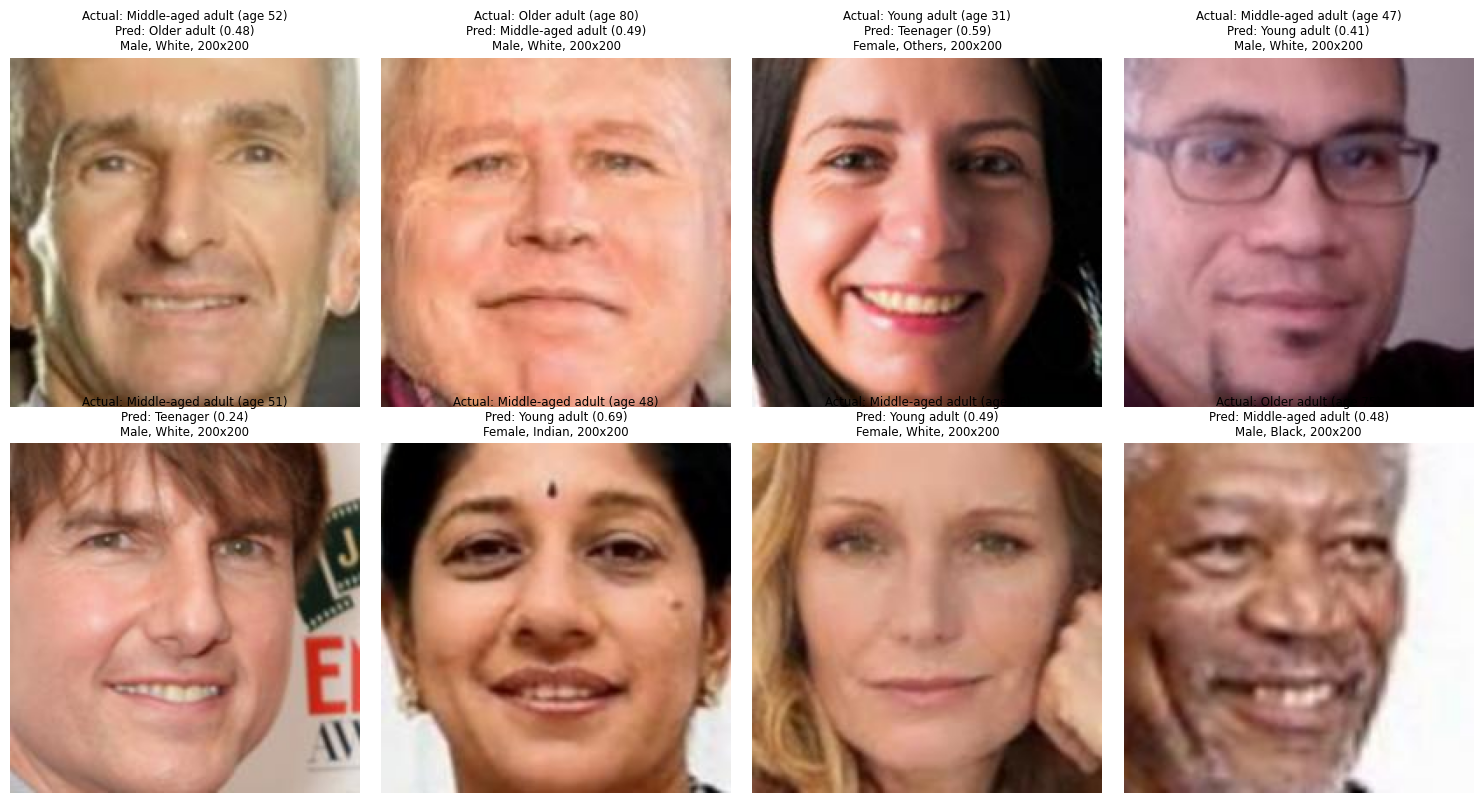

,file,age,y_true,y_pred,confidence
0,52_0_0_20170104211941860.jpg.chip.jpg,52,3,4,0.483370
1,80_0_0_20170117171459531.jpg.chip.jpg,80,4,3,0.493309
2,31_1_4_20161221193717222.jpg.chip.jpg,31,2,1,0.586393
3,47_0_0_20170117160016192.jpg.chip.jpg,47,3,2,0.414465
4,51_0_0_20170111171747345.jpg.chip.jpg,51,3,1,0.238572
5,48_1_3_20170104220351694.jpg.chip.jpg,48,3,2,0.692011
6,46_1_0_20170104235700307.jpg.chip.jpg,46,3,2,0.485382
7,75_0_1_20170113135403273.jpg.chip.jpg,75,4,3,0.478830


In [29]:
mis = test_df[~test_df.correct].sample(frac=1, random_state=SEED).reset_index(drop=True)
print(f'Misclassified: {len(mis)} / {len(test_df)} ({len(mis)/len(test_df):.1%})')
show = mis.head(8)
fig, axes = plt.subplots(2, 4, figsize=(15, 8))
for ax, (_, r) in zip(axes.ravel(), show.iterrows()):
    im = Image.open(r.path).convert('RGB')
    ax.imshow(im); ax.axis('off')
    ax.set_title(f'Actual: {AGE_GROUPS[r.y_true]} (age {r.age})\nPred: {AGE_GROUPS[r.y_pred]} ({r.confidence:.2f})\n'
                 f'{r.gender_name}, {r.race_name}, {im.size[0]}x{im.size[1]}', fontsize=8.5)
plt.tight_layout(); savefig('t7a_misclassified.png'); plt.show()
display(show[['file', 'age', 'y_true', 'y_pred', 'confidence']])

### Part B: LIME explanation

In [30]:
from lime import lime_image
from skimage.segmentation import mark_boundaries

to_norm = transforms.Compose([transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

def load_rgb224(path):  # identical resize to the Task 3/4 pipeline
    return np.array(Image.open(path).convert('RGB').resize((224, 224), Image.BILINEAR))

def predict_fn(images):  # batch of HxWx3 RGB arrays -> (N, 5) probabilities
    batch = torch.stack([to_norm(Image.fromarray(im.astype(np.uint8))) for im in images]).to(device)
    with torch.no_grad():
        return torch.softmax(model(batch), 1).cpu().numpy()

explainer = lime_image.LimeImageExplainer(random_state=SEED)

def lime_explain(row, tag, num_samples=1000):
    img = load_rgb224(row.path)
    exp = explainer.explain_instance(img, predict_fn, top_labels=5, hide_color=0,
                                     num_samples=num_samples, batch_size=64, random_seed=SEED)
    lab = int(row.y_pred)
    pos_img, pos_mask = exp.get_image_and_mask(lab, positive_only=True, num_features=5, hide_rest=False)
    pn_img, pn_mask   = exp.get_image_and_mask(lab, positive_only=False, num_features=10, hide_rest=False)
    fig, ax = plt.subplots(1, 3, figsize=(13, 4.5))
    ax[0].imshow(img); ax[0].set_title(f'Original\nActual: {AGE_GROUPS[row.y_true]} | Pred: {AGE_GROUPS[lab]} ({row.confidence:.2f})', fontsize=9)
    ax[1].imshow(mark_boundaries(pos_img / 255.0, pos_mask)); ax[1].set_title('Top-5 superpixels supporting prediction', fontsize=9)
    ax[2].imshow(mark_boundaries(pn_img / 255.0, pn_mask)); ax[2].set_title('Green = supports, red = against', fontsize=9)
    for a in ax: a.axis('off')
    plt.tight_layout(); savefig(f't7b_lime_{tag}.png'); plt.show()
    print(f'{tag}: actual={AGE_GROUPS[row.y_true]}, predicted={AGE_GROUPS[lab]}, confidence={row.confidence:.4f}')
    print('class probabilities:', dict(zip(AGE_GROUPS, predict_fn(img[None])[0].round(3))))
    return exp

correct_row = test_df[test_df.correct].sample(1, random_state=SEED).iloc[0]
wrong_row   = mis.iloc[0]

  0%|          | 0/1000 [00:00<?, ?it/s]

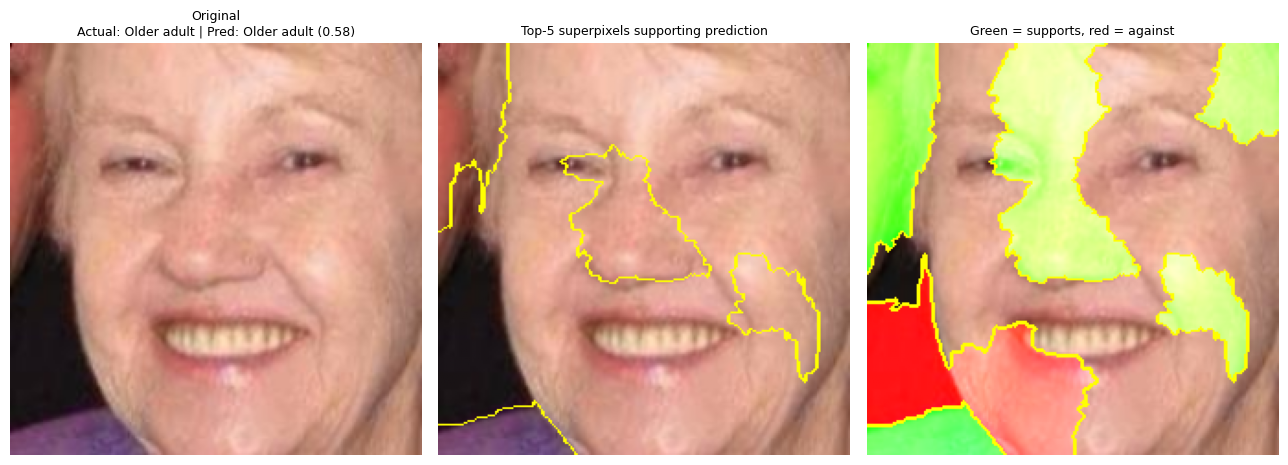

correct: actual=Older adult, predicted=Older adult, confidence=0.5779
class probabilities: {'Child': np.float32(0.005), 'Teenager': np.float32(0.007), 'Young adult': np.float32(0.059), 'Middle-aged adult': np.float32(0.351), 'Older adult': np.float32(0.578)}


In [31]:
exp_correct = lime_explain(correct_row, 'correct')

  0%|          | 0/1000 [00:00<?, ?it/s]

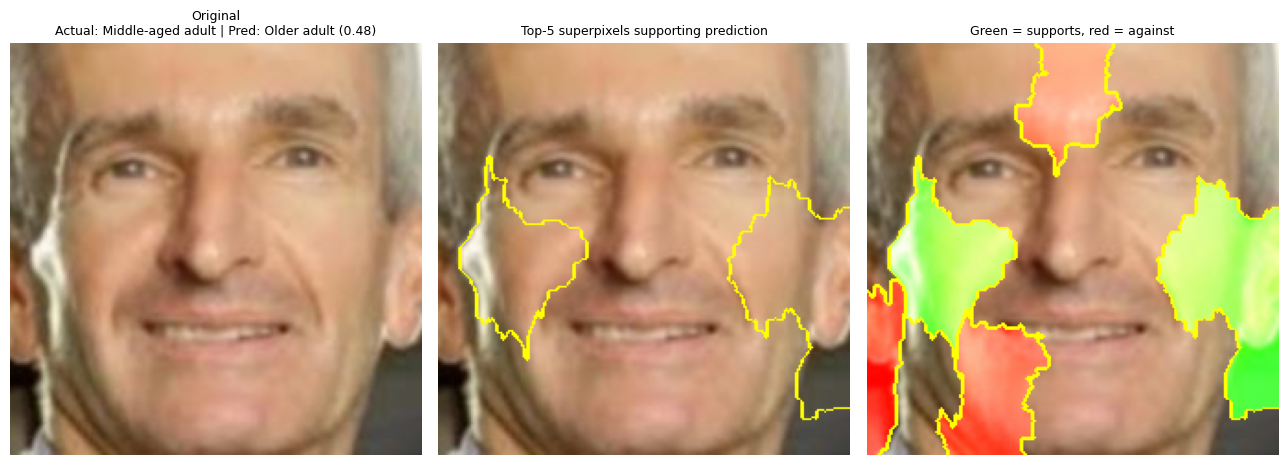

misclassified: actual=Middle-aged adult, predicted=Older adult, confidence=0.4834
class probabilities: {'Child': np.float32(0.007), 'Teenager': np.float32(0.007), 'Young adult': np.float32(0.15), 'Middle-aged adult': np.float32(0.353), 'Older adult': np.float32(0.483)}


In [32]:
exp_wrong = lime_explain(wrong_row, 'misclassified')

### Part C: Grad-CAM (optional extension)

In [33]:
from captum.attr import LayerGradCam, LayerAttribution
gradcam = LayerGradCam(model, model.layer4)   # last conv stage of ResNet-18

def gradcam_show(row, tag):
    orig = np.array(Image.open(row.path).convert('RGB'))
    H, W = orig.shape[:2]
    x = to_norm(Image.fromarray(load_rgb224(row.path))).unsqueeze(0).to(device).requires_grad_(True)
    attr = gradcam.attribute(x, target=int(row.y_pred), relu_attributions=True)          # (1,1,7,7)
    attr = LayerAttribution.interpolate(attr, (H, W), interpolate_mode='bilinear')       # to original size
    heat = attr.squeeze().detach().cpu().numpy()
    heat = (heat - heat.min()) / (heat.max() - heat.min() + 1e-8)
    fig, ax = plt.subplots(1, 3, figsize=(13, 4.5))
    ax[0].imshow(orig); ax[0].set_title(f'Actual: {AGE_GROUPS[row.y_true]} | Pred: {AGE_GROUPS[row.y_pred]}', fontsize=9)
    ax[1].imshow(heat, cmap='jet'); ax[1].set_title('Grad-CAM heatmap (layer4)', fontsize=9)
    ax[2].imshow(orig); ax[2].imshow(heat, cmap='jet', alpha=0.45); ax[2].set_title('Overlay', fontsize=9)
    for a in ax: a.axis('off')
    plt.tight_layout(); savefig(f't7c_gradcam_{tag}.png'); plt.show()

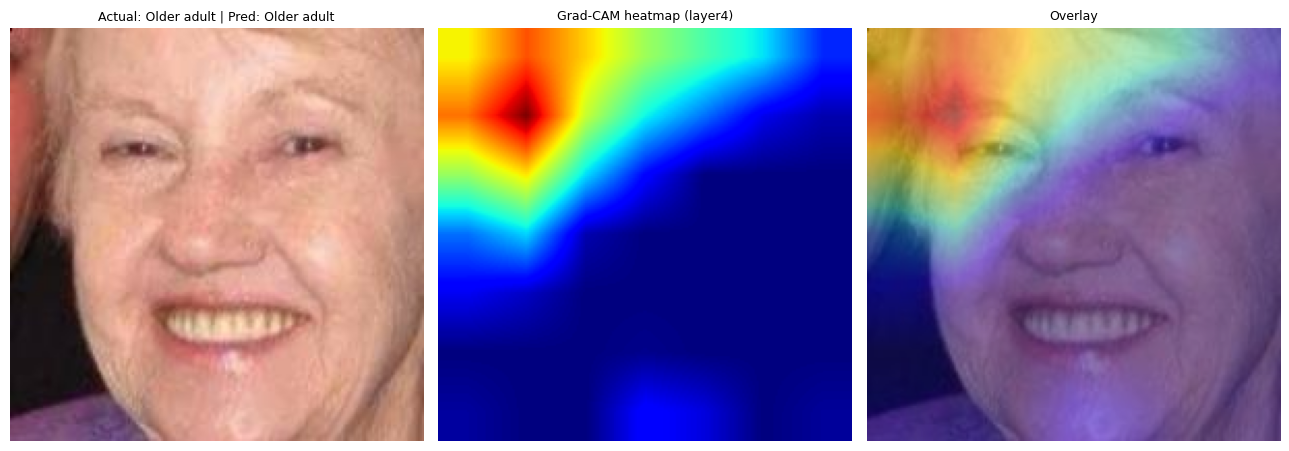

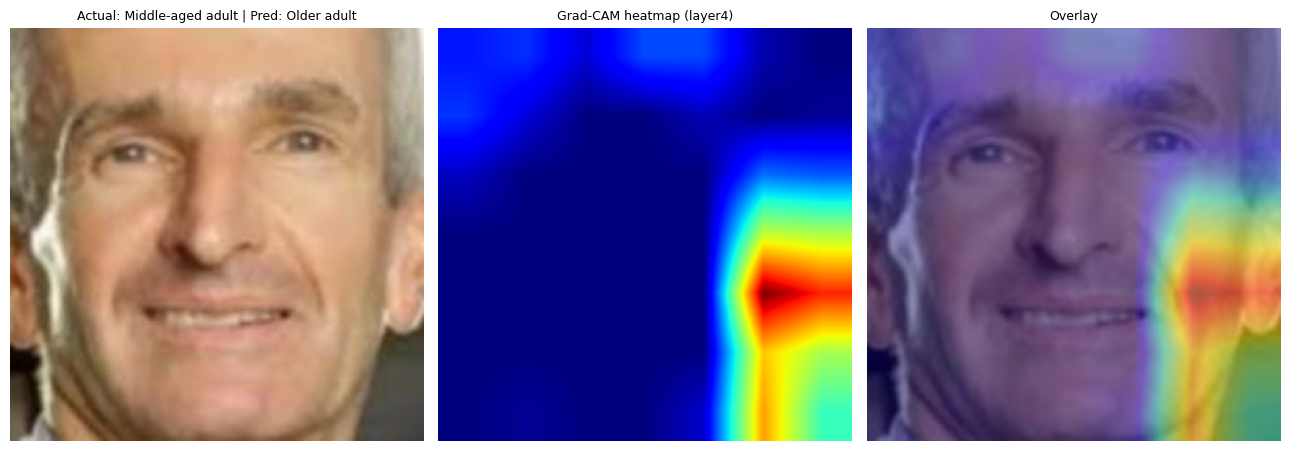

In [34]:
gradcam_show(correct_row, 'correct')
gradcam_show(wrong_row, 'misclassified')

## Task 8: Results Consolidation and Critical Discussion

In [35]:
results = pd.Series({
    'Total image files': len(all_files),
    'Total valid images': len(df),
    'Train / Val / Test': f'{len(train_df)} / {len(val_df)} / {len(test_df)}',
    'Test accuracy': round(acc, 4),
    'Balanced accuracy': round(bacc, 4),
    'Macro F1-score': round(mf1, 4),
    'Best validation epoch': f'{best_epoch} (val acc {best_val_acc:.4f})',
    'Best age group (recall)': f'{classwise.recall.idxmax()} ({classwise.recall.max():.4f})',
    'Weakest age group (recall)': f'{classwise.recall.idxmin()} ({classwise.recall.min():.4f})',
    'Best age group (F1)': f"{classwise['f1-score'].idxmax()} ({classwise['f1-score'].max():.4f})",
    'Weakest age group (F1)': f"{classwise['f1-score'].idxmin()} ({classwise['f1-score'].min():.4f})",
}, name='value')
display(results.to_frame())
results.to_csv(f'{OUT_DIR}/final_results_table.csv')

,value
Total image files,23708
Total valid images,23315
Train / Val / Test,16320 / 3497 / 3498
Test accuracy,0.7173
Balanced accuracy,0.5617
Macro F1-score,0.5965
Best validation epoch,4 (val acc 0.7252)
Best age group (recall),Young adult (0.9172)
Weakest age group (recall),Teenager (0.1897)
Best age group (F1),Child (0.8432)


In [39]:
import shutil
shutil.make_archive('/kaggle/working/exp9_outputs', 'zip', OUT_DIR)
from IPython.display import FileLink
FileLink('exp9_outputs.zip')

/kaggle/working/exp9_outputs.zip